# Full reproducible analysis: EDA, features, ranking, tests, ML

This analysis notebook starts from the integrated panel `data/processed/ssot_historical.csv`; it does not repeat the NVD history download.

In [17]:
from pathlib import Path
import sys
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display
ROOT=Path.cwd(); ROOT=ROOT if (ROOT/'data/processed/ssot_historical.csv').exists() else ROOT.parent
P=ROOT/'data/processed/ssot_historical.csv'; T=ROOT/'outputs/tables'; assert P.exists(),f'Missing {P}'
cols=['cve_id','published_date','decision_date','kev_date_added','kev_30d_label','epss_at_decision','epss_percentile_at_decision','cvss_score_asof','cvss_version_asof','cvss_severity_asof','cvss_v3','cve_age_days','attack_vector_asof','attack_complexity_asof','privileges_required_asof','user_interaction_asof','scope_asof','confidentiality_impact_asof','integrity_impact_asof','availability_impact_asof','cwe','cvss_score']
df=pd.read_csv(P,usecols=cols,parse_dates=['published_date','decision_date','kev_date_added'],low_memory=False)
for c in ['kev_30d_label','epss_at_decision','epss_percentile_at_decision','cvss_score_asof','cvss_v3','cve_age_days']: df[c]=pd.to_numeric(df[c],errors='coerce')
df.kev_30d_label=df.kev_30d_label.fillna(0).astype('int8'); df['cvss_v3']=df.cvss_score_asof.where(df.cvss_version_asof.astype(str).isin(['3.0','3.1']))
print(len(df),'CVE-date rows;',df.cve_id.nunique(),'CVE IDs;',df.kev_30d_label.sum(),'positive rows')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


934180 CVE-date rows; 206865 CVE IDs; 109 positive rows


## EDA and data quality

### DataFrame summary

In [18]:
# Compact DataFrame summary: dimensions, types, missingness, cardinality, and numeric stats.
df_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'unique': df.nunique(dropna=True),
})
numeric_summary = df.describe(include=[np.number]).T
df_summary = df_summary.join(numeric_summary[['mean','std','min','25%','50%','75%','max']], how='left')
display(df_summary)
print(f'DataFrame shape: {df.shape[0]:,} rows × {df.shape[1]} columns')

,dtype,non_null,missing,missing_pct,unique,mean,std,min,25%,50%,75%,max
cve_id,str,934180,0,0.00,206865,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,datetime64[us],934180,0,0.00,1998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cvss_score,float64,931565,2615,0.28,91,7.031027,1.702579e+00,0.00000,5.50000,7.20000,8.10000,10.00000
cwe,str,846813,87367,9.35,5073,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cve_age_days,int64,934180,0,0.00,2036,611.985780,4.691718e+02,1.00000,222.00000,508.00000,913.00000,2056.00000
kev_date_added,datetime64[us],705,933475,99.92,172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
epss_at_decision,float64,933597,583,0.06,21359,0.013383,7.017527e-02,0.00001,0.00057,0.00167,0.00556,0.99999
epss_percentile_at_decision,float64,933597,583,0.06,97461,0.362181,2.456200e-01,0.00000,0.16363,0.30687,0.51708,0.99999
decision_date,datetime64[us],934180,0,0.00,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kev_30d_label,int8,934180,0,0.00,2,0.000117,1.080122e-02,0.00000,0.00000,0.00000,0.00000,1.00000


DataFrame shape: 934,180 rows × 22 columns


,decision_date,rows,unique_cves,positives,prevalence,missing_epss,missing_cvss
0,2022-02-19,19484,19484,10,0.000513,0.001488,0.101673
1,2022-08-19,31132,31132,10,0.000321,0.000161,0.076706
2,2023-02-19,43662,43662,8,0.000183,0.000046,0.085154
3,2023-08-19,57322,57322,6,0.000105,0.000035,0.077352
4,2024-02-19,71940,71940,4,0.000056,0.000250,0.062552
5,2024-08-19,92895,92895,10,0.000108,0.005565,0.107164
6,2025-02-19,113382,113382,16,0.000141,0.000018,0.073001
7,2025-08-19,136374,136374,6,0.000044,0.000029,0.077485
8,2026-02-19,161402,161402,20,0.000124,0.000012,0.070569
9,2026-08-19,206587,206587,19,0.000092,0.000010,0.080755


Label mismatches: 0


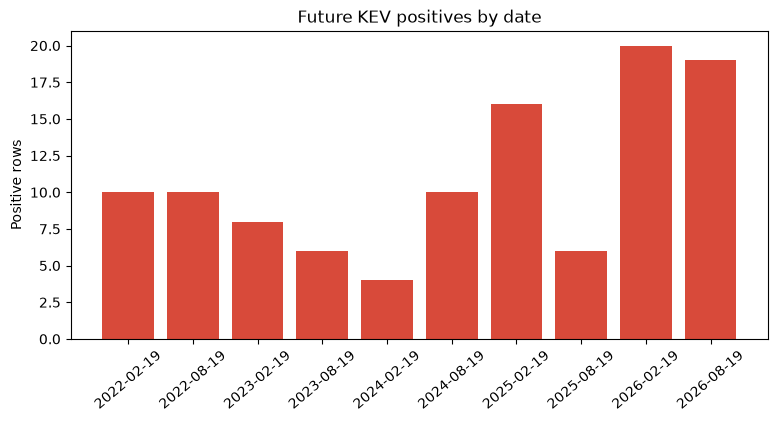

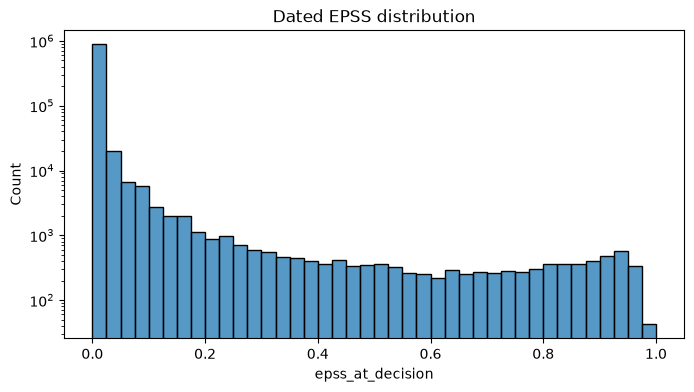

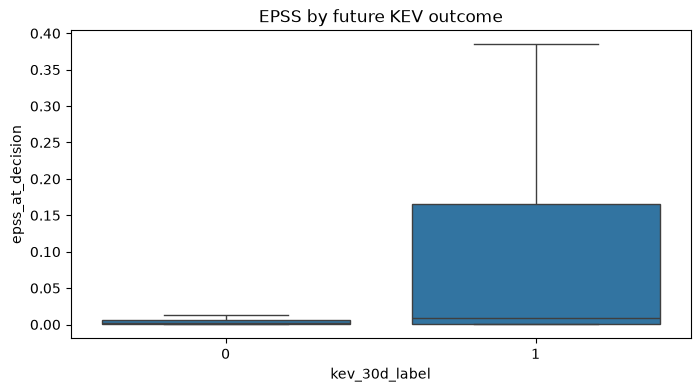

,missing_fraction
cvss_v3,0.079099
epss_at_decision,0.000624
epss_percentile_at_decision,0.000624
cve_age_days,0.000000


In [19]:
summary=df.groupby('decision_date').agg(rows=('cve_id','size'),unique_cves=('cve_id','nunique'),positives=('kev_30d_label','sum'),prevalence=('kev_30d_label','mean'),missing_epss=('epss_at_decision',lambda x:x.isna().mean()),missing_cvss=('cvss_v3',lambda x:x.isna().mean())).reset_index(); display(summary)
expected=(df.kev_date_added.gt(df.decision_date)&df.kev_date_added.le(df.decision_date+pd.Timedelta(days=30))).fillna(False).astype('int8'); print('Label mismatches:',(expected!=df.kev_30d_label).sum()); assert (expected==df.kev_30d_label).all()
fig,ax=plt.subplots(figsize=(9,4)); ax.bar(summary.decision_date.dt.strftime('%Y-%m-%d'),summary.positives,color='#d84a3a'); ax.set(title='Future KEV positives by date',ylabel='Positive rows'); ax.tick_params(axis='x',rotation=40); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.histplot(df.epss_at_decision.dropna(),bins=40,ax=ax); ax.set(title='Dated EPSS distribution',yscale='log'); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.boxplot(data=df,x='kev_30d_label',y='epss_at_decision',showfliers=False,ax=ax); ax.set(title='EPSS by future KEV outcome'); plt.show()
display(df[['cvss_v3','epss_at_decision','epss_percentile_at_decision','cve_age_days']].isna().mean().to_frame('missing_fraction'))

## Feature engineering and leakage controls

CVSS is normalized to 0–1; combined ranking is the project’s equal-weight mean of normalized CVSS and dated EPSS. Model predictors are historical CVSS, age, historical vector features, plus EPSS in the second feature set. Current NVD enrichment, date/model version, and the target are excluded. Preprocessing is trained within pipeline.

,feature,source,use
0,CVSS 3.x,Historical NVD,Base predictor
1,CVE age,Derived,Base predictor
2,CVSS vector,Historical NVD,Categorical predictors
3,EPSS probability/percentile,Dated FIRST,EPSS feature set only
4,KEV 30-day label,KEV dates,Target only
5,Current CWE/CVSS/CPE,Current NVD,Excluded: leakage risk


,decile,rows,positives,rate
0,1,93360,8,0.000086
1,2,93360,9,0.000096
2,3,93359,4,0.000043
3,4,93360,6,0.000064
4,5,93360,4,0.000043
5,6,93359,6,0.000064
6,7,93360,8,0.000086
7,8,93359,7,0.000075
8,9,93360,15,0.000161
9,10,93360,42,0.000450


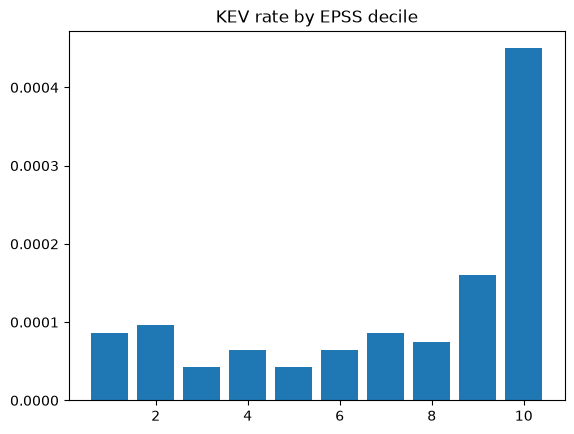

In [20]:
df['cvss_normalized']=df.cvss_v3/10; df['combined_score']=.5*df.cvss_normalized+.5*df.epss_at_decision
display(pd.DataFrame([('CVSS 3.x','Historical NVD','Base predictor'),('CVE age','Derived','Base predictor'),('CVSS vector','Historical NVD','Categorical predictors'),('EPSS probability/percentile','Dated FIRST','EPSS feature set only'),('KEV 30-day label','KEV dates','Target only'),('Current CWE/CVSS/CPE','Current NVD','Excluded: leakage risk')],columns=['feature','source','use']))
e=df.dropna(subset=['epss_at_decision']).copy(); e['decile']=pd.qcut(e.epss_at_decision.rank(method='first'),10,labels=False)+1; dec=e.groupby('decile',observed=True).agg(rows=('cve_id','size'),positives=('kev_30d_label','sum'),rate=('kev_30d_label','mean')).reset_index(); display(dec); plt.bar(dec.decile,dec.rate); plt.title('KEV rate by EPSS decile'); plt.show()

## Ranking metrics and hypothesis tests

Available-cohort ranking reflects method-specific coverage; paired comparisons use rows with both CVSS 3.x and EPSS. Recall@K is positive capture; Precision@K is list purity.

In [21]:
KS=(50,100,500,1000); methods={'CVSS-only':'cvss_v3','EPSS-only':'epss_at_decision','Combined':'combined_score'}
from scripts.ranking_utils import expected_recall_precision_at_k
def metric(y,s,k):
    result=expected_recall_precision_at_k(y,s,[k])[k]
    return result[0],result[1]
common=df[df.cvss_v3.notna()&df.epss_at_decision.notna()].copy(); out=[]
for cohort,g0 in [('available',df),('common',common)]:
    for name,col in methods.items():
        g=g0.dropna(subset=[col])
        for k in KS:
            r,p=metric(g.kev_30d_label,g[col],k)
            out.append({'cohort':cohort,'method':name,'K':k,'rows':len(g),'positives':int(g.kev_30d_label.sum()),'recall':r,'precision':p})
rankings=pd.DataFrame(out); display(rankings.query("cohort=='common'").pivot(index='K',columns='method',values=['recall','precision']))
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
pos=df.loc[df.kev_30d_label.eq(1),'epss_at_decision'].dropna(); neg=df.loc[df.kev_30d_label.eq(0),'epss_at_decision'].dropna(); print('H1 pooled one-sided Mann-Whitney:',mannwhitneyu(pos,neg,alternative='greater',method='asymptotic'))

recall                     precision                   
method CVSS-only  Combined EPSS-only CVSS-only Combined EPSS-only
K                                                                
50           0.0  0.010101  0.010101       0.0    0.020     0.020
100          0.0  0.020202  0.010101       0.0    0.020     0.010
500          0.0  0.040404  0.040404       0.0    0.008     0.008
1000         0.0  0.050505  0.050505       0.0    0.005     0.005

H1 pooled one-sided Mann-Whitney: MannwhitneyuResult(statistic=np.float64(69325872.5), pvalue=np.float64(2.7188112137261004e-11))


In [22]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from statsmodels.stats.multitest import multipletests

root = Path.cwd()
if not (root / "outputs/tables/ranking_paired_tests.csv").exists():
    root = root.parent
paired_path = root / "outputs/tables/ranking_paired_tests.csv"
if paired_path.exists():
    paired_results = pd.read_csv(paired_path)
    paired_results["p_holm"] = paired_results.groupby("hypothesis")["bootstrap_two_sided_p"].transform(
        lambda p: multipletests(p, method="holm")[1]
    )
    pooled = paired_results.loc[paired_results["decision_date"].eq("POOLED")]
    display(pooled[["hypothesis", "k", "recall_difference", "bootstrap_ci_low", "bootstrap_ci_high", "bootstrap_two_sided_p", "p_holm", "positives", "pool_size"]])
else:
    raise FileNotFoundError(f"Missing {paired_path}; run scripts/03_analyze.py first.")

,hypothesis,k,recall_difference,bootstrap_ci_low,bootstrap_ci_high,bootstrap_two_sided_p,p_holm,positives,pool_size
40,H2 EPSS vs CVSS,50,0.010101,0.000000,0.032609,0.182724,1.000000,99,859971
41,H2 EPSS vs CVSS,100,0.010101,0.000000,0.034115,0.504983,1.000000,99,859971
42,H2 EPSS vs CVSS,500,0.040404,0.009520,0.082134,0.046512,1.000000,99,859971
43,H2 EPSS vs CVSS,1000,0.050505,0.009804,0.093016,0.016611,0.647841,99,859971
84,H3 Combined vs CVSS,50,0.010101,0.000000,0.032797,0.162791,1.000000,99,859971
85,H3 Combined vs CVSS,100,0.020202,0.000000,0.050265,0.209302,1.000000,99,859971
86,H3 Combined vs CVSS,500,0.040404,0.000000,0.082925,0.069767,1.000000,99,859971
87,H3 Combined vs CVSS,1000,0.050505,0.011426,0.094268,0.016611,0.664452,99,859971


## ML models and date-forward results

Train on all but the final two dates; validate on the penultimate and test on the last. Compare Logistic Regression, Random Forest, XGBoost, with and without EPSS. Average Precision emphasizes the rare positive class.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
cat=['cvss_version_asof','cvss_severity_asof','attack_vector_asof','attack_complexity_asof','privileges_required_asof','user_interaction_asof','scope_asof','confidentiality_impact_asof','integrity_impact_asof','availability_impact_asof']
for c in cat: df[c]=df[c].map(lambda x:str(x) if pd.notna(x) else 'Unknown')
dates=sorted(df.decision_date.dropna().unique()); train=df[df.decision_date.isin(dates[:-2])]; val=df[df.decision_date.eq(dates[-2])]; test=df[df.decision_date.eq(dates[-1])]; print('Train dates',pd.to_datetime(dates[:-2]).strftime('%Y-%m-%d').tolist(),'validation/test',dates[-2:], 'test positives',test.kev_30d_label.sum())

Train dates ['2022-02-19', '2022-08-19', '2023-02-19', '2023-08-19', '2024-02-19', '2024-08-19', '2025-02-19', '2025-08-19'] validation/test [Timestamp('2026-02-19 00:00:00'), Timestamp('2026-08-19 00:00:00')] test positives 19


,model,feature_set,split,rows,positives,average_precision,recall@50,recall@100,recall@500,recall@1000
7,Logistic Regression,With EPSS,test,206587,19,0.007346,0.105263,0.105263,0.210526,0.210526
1,Logistic Regression,Without EPSS,test,206587,19,0.002086,0.000000,0.000000,0.157895,0.210526
9,Random Forest,With EPSS,test,206587,19,0.000483,0.000000,0.000000,0.000000,0.052632
3,Random Forest,Without EPSS,test,206587,19,0.000253,0.000000,0.000000,0.000000,0.000000
11,XGBoost,With EPSS,test,206587,19,0.000991,0.000000,0.000000,0.105263,0.105263
5,XGBoost,Without EPSS,test,206587,19,0.000269,0.000000,0.000000,0.000000,0.000000


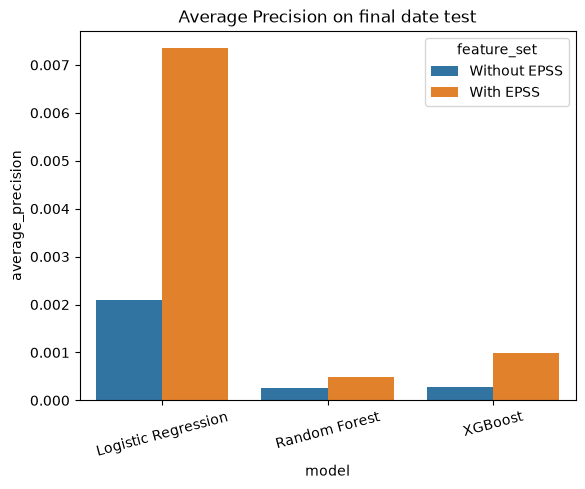

In [24]:
models_out=[]; base=['cvss_v3','cve_age_days']
for eps in (False,True):
 num=base+(['epss_at_decision','epss_percentile_at_decision'] if eps else []); prep=ColumnTransformer([('n',Pipeline([('i',SimpleImputer(strategy='median',add_indicator=True)),('s',StandardScaler())]),num),('c',Pipeline([('i',SimpleImputer(strategy='constant',fill_value='Unknown')),('o',OneHotEncoder(handle_unknown='ignore',min_frequency=100))]),cat)])
 yt=train.kev_30d_label.to_numpy(int); ratio=(len(yt)-yt.sum())/max(yt.sum(),1); models={'Logistic Regression':LogisticRegression(class_weight='balanced',max_iter=500,solver='liblinear',random_state=20261118),'Random Forest':RandomForestClassifier(n_estimators=250,max_depth=12,min_samples_leaf=20,class_weight='balanced_subsample',n_jobs=1,random_state=20261118),'XGBoost':XGBClassifier(n_estimators=250,max_depth=4,learning_rate=.04,subsample=.8,colsample_bytree=.8,reg_lambda=2,scale_pos_weight=ratio,objective='binary:logistic',eval_metric='aucpr',n_jobs=4,random_state=20261118)}
 for name,est in models.items():
  pipe=Pipeline([('prep',prep),('m',est)]); pipe.fit(train[num+cat],yt)
  for split,g in [('validation',val),('test',test)]:
   yy=g.kev_30d_label.to_numpy(int); pred=pipe.predict_proba(g[num+cat])[:,1]; row={'model':name,'feature_set':'With EPSS' if eps else 'Without EPSS','split':split,'rows':len(g),'positives':int(yy.sum()),'average_precision':average_precision_score(yy,pred) if yy.sum() else np.nan}
   for k in KS: row['recall@'+str(k)]=metric(yy,pred,k)[0]
   models_out.append(row)
model_results=pd.DataFrame(models_out); display(model_results.query("split=='test'").sort_values(['model','feature_set']))
sns.barplot(data=model_results.query("split=='test'"),x='model',y='average_precision',hue='feature_set'); plt.title('Average Precision on final date test'); plt.xticks(rotation=15); plt.show()


In [ ]:
# Dynamic study-size and pooled top-1,000 summary; avoids stale hardcoded counts.
summary_rows=int(len(df)); positive_rows=int(df.kev_30d_label.sum()); common_rows=int(len(common)); common_positives=int(common.kev_30d_label.sum())
result_rows=[]
for name,col in methods.items():
    recall,precision=metric(common.kev_30d_label,common[col],1000)
    result_rows.append({'Ranking':name,'Common rows':common_rows,'Positive rows':common_positives,'Expected hits at K=1,000':recall*common_positives,'Recall@1,000':recall,'Precision@1,000':precision})
display(pd.DataFrame([{'CVE-date rows':summary_rows,'Positive rows':positive_rows,'Unique CVEs':df.cve_id.nunique(),'Dates':df.decision_date.nunique(),'Common cohort rows':common_rows,'Common cohort positives':common_positives,'Final test positives':int(test.kev_30d_label.sum())}]))
display(pd.DataFrame(result_rows).style.format({'CVE-date rows':'{:,.0f}','Positive rows':'{:,.0f}','Unique CVEs':'{:,.0f}','Common cohort rows':'{:,.0f}','Common cohort positives':'{:,.0f}','Final test positives':'{:,.0f}','Expected hits at K=1,000':'{:.2f}','Recall@1,000':'{:.3f}','Precision@1,000':'{:.4%}'}))

## Interpretation and caveats

The table immediately above computes cohort sizes and expected top-1,000 hits from the loaded historical panel using tie-aware metrics. The final test date has few positives, so performance estimates remain provisional. KEV additions are catalogue dates rather than attack times, and CVEs recur across snapshots. The project report and saved output tables provide the broader results.

# Beyond CVSS
## Does EPSS help a security team choose what to patch first?

**Advanced Data Science · BML Munjal University**  
**Presenters:** Sumit Sharma and Ayansh Pandey  
**Data:** ten decision snapshots, February 2022–August 2026

> **Talk track:** We compare three ways to rank vulnerabilities under a fixed patching budget: historical CVSS, dated EPSS, and a simple combination. The outcome is whether CISA added a CVE to KEV within 30 days after a decision date.

**Suggested presentation flow (8–10 minutes):** problem → data and time-aware CVSS → ranking results → model check → recommendation.

## 1. The decision problem

Security teams often have more open vulnerabilities than they can patch at once. The practical question is: **if the team can patch only the top _K_ items, which ranking captures more CVEs that will soon be added to CISA KEV?**

- **CVSS** describes vulnerability severity.
- **EPSS** estimates the probability of exploitation over the next 30 days.
- **Recall@K** is the share of future KEV additions found in the top _K_.
- **Precision@K** is the share of the top _K_ that become KEV additions.

**Presenter cue:** Emphasize that the target is a later *catalogue addition*, not the exact time an attacker first exploited a vulnerability.

## 2. How the historical comparison works

Each snapshot uses the EPSS file for that decision date. The panel includes CVEs published before the date, excludes CVEs already in KEV, and labels a CVE positive if `dateAdded` falls in the following 30 days.

CVSS 3.x is reconstructed from timestamped NVD change history, using the last vector recorded **strictly before 00:00 UTC** on the decision date. Current CVSS is kept for audit and never fills a historical gap. Other NVD enrichment fields can reflect current records, so they are excluded from model predictors.

The pooled ranking stacks historical CVE-date rows. It describes repeated decision opportunities; it is **not** one real-time patch queue.

In [25]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Find the project root whether Jupyter starts here or in notebooks/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "outputs" / "tables" / "ranking_results.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the project folder or one of its subfolders.")
TABLES = ROOT / "outputs" / "tables"

panel = pd.read_csv(TABLES / "panel_summary.csv", parse_dates=["decision_date"])
cvss_coverage = pd.read_csv(TABLES / "historical_cvss_coverage.csv", parse_dates=["decision_date"])
ranking = pd.read_csv(TABLES / "ranking_results.csv")
per_date_summary = pd.read_csv(TABLES / "ranking_per_date_summary.csv")
tests = pd.read_csv(TABLES / "test_results.csv")
models = pd.read_csv(TABLES / "model_results.csv")

NAVY, TEAL, ORANGE, GREY = "#19344F", "#177E78", "#CF8741", "#65727D"
plt.rcParams.update({"figure.figsize": (10, 5.5), "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 15,
                     "axes.labelsize": 12, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
rows = int(panel["rows"].sum())
positives = int(panel["positives"].sum())
coverage = cvss_coverage["historical_cvss_3x_rate"].mean()
display(Markdown(f"**Loaded saved results:** {len(panel)} decision dates · {rows:,} CVE-date rows · {positives} future KEV labels · mean historical CVSS 3.x coverage {coverage:.1%}."))

**Loaded project results:** 10 decision dates · 934,180 CVE-date rows · 109 future KEV labels · mean date-level historical CVSS 3.x coverage 91.9%.

### Snapshot scale and rare outcomes

The pool grows over time as more CVEs become eligible. KEV additions remain rare in every snapshot, so a model can look strong on accuracy while missing most positive cases. This is why the project focuses on Recall@K, Precision@K, and Average Precision.

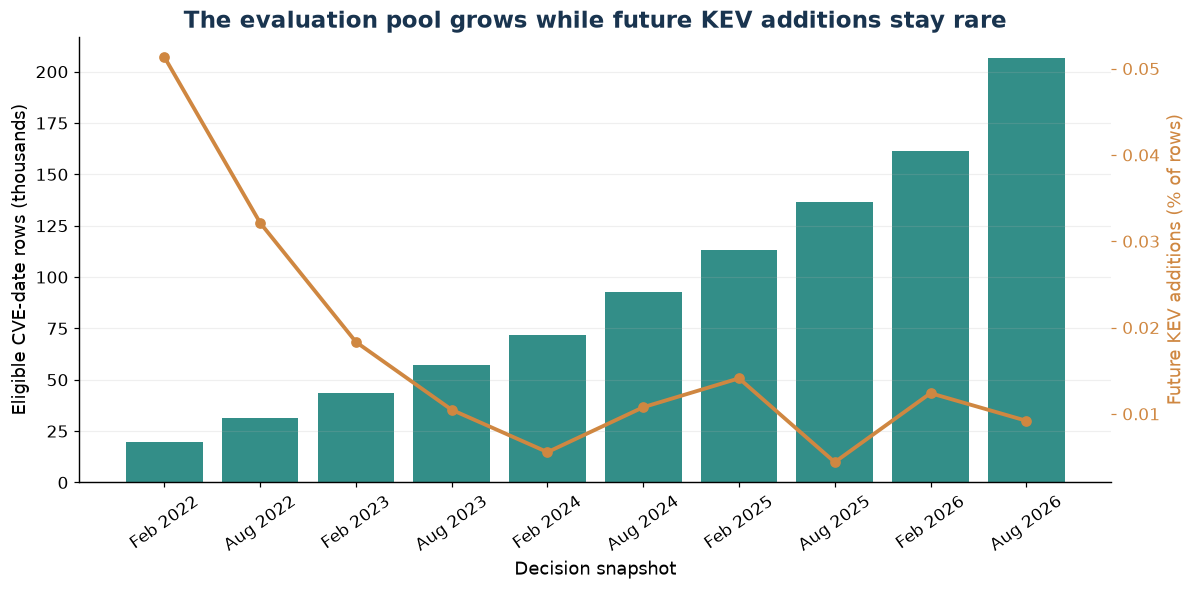

,Decision date,Eligible rows,Future KEV additions,Positive rate
0,2022-02-19 00:00:00,"19,484",10,0.051%
1,2022-08-19 00:00:00,"31,132",10,0.032%
2,2023-02-19 00:00:00,"43,662",8,0.018%
3,2023-08-19 00:00:00,"57,322",6,0.010%
4,2024-02-19 00:00:00,"71,940",4,0.006%
5,2024-08-19 00:00:00,"92,895",10,0.011%
6,2025-02-19 00:00:00,"113,382",16,0.014%
7,2025-08-19 00:00:00,"136,374",6,0.004%
8,2026-02-19 00:00:00,"161,402",20,0.012%
9,2026-08-19 00:00:00,"206,587",19,0.009%


In [26]:
plot = panel.copy()
plot["date_label"] = plot["decision_date"].dt.strftime("%b %Y")
plot["positive_rate_pct"] = plot["positive_rate"] * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(plot["date_label"], plot["rows"] / 1000, color=TEAL, alpha=.88)
ax.set_ylabel("Eligible CVE-date rows (thousands)")
ax.set_xlabel("Decision snapshot")
ax.tick_params(axis="x", rotation=35)
ax.set_title("The evaluation pool grows while future KEV additions stay rare", color=NAVY)
ax.grid(axis="y", alpha=.2)
ax2 = ax.twinx()
ax2.plot(plot["date_label"], plot["positive_rate_pct"], color=ORANGE, marker="o", linewidth=2.5)
ax2.set_ylabel("Future KEV additions (% of rows)", color=ORANGE)
ax2.tick_params(axis="y", colors=ORANGE)
fig.tight_layout()
plt.show()

display(plot[["decision_date", "rows", "positives", "positive_rate"]].rename(columns={
    "decision_date": "Decision date", "rows": "Eligible rows", "positives": "Future KEV additions", "positive_rate": "Positive rate"
}).style.format({"Eligible rows": "{:,.0f}", "Future KEV additions": "{:,.0f}", "Positive rate": "{:.3%}"}))

### Historical CVSS coverage

NVD history does not contain a usable 3.x vector for every CVE/date. Missing historical scores stay missing, so CVSS-only and combined rankings use only rows with a historical 3.x score. EPSS-only can use a larger pool. The paired comparison uses a common complete-case cohort.

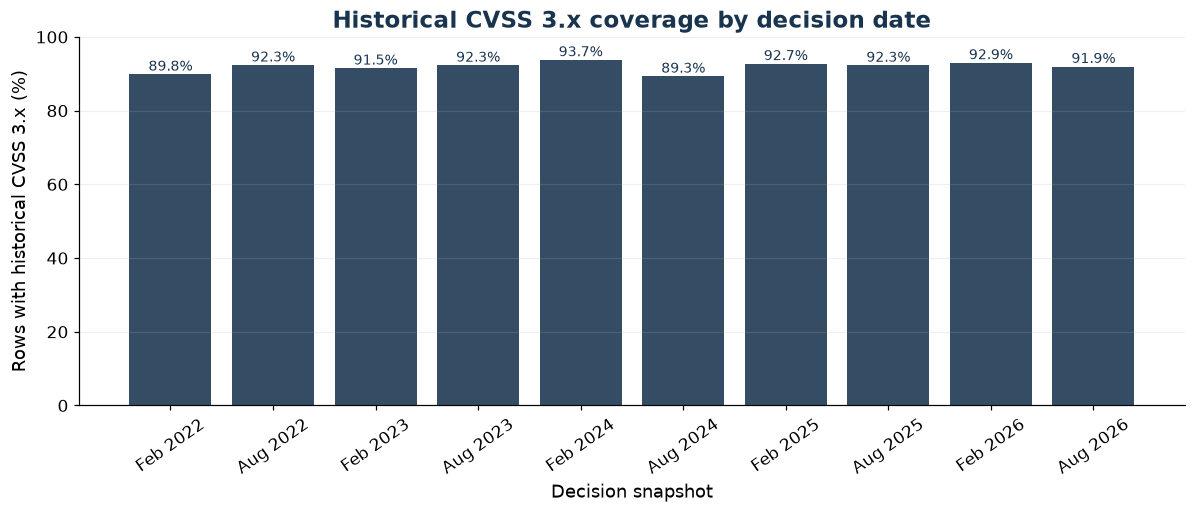

Coverage ranges from **89.3% to 93.7%** across dates.

In [27]:
coverage_plot = cvss_coverage.copy()
coverage_plot["date_label"] = coverage_plot["decision_date"].dt.strftime("%b %Y")
coverage_plot["coverage_pct"] = coverage_plot["historical_cvss_3x_rate"] * 100

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(coverage_plot["date_label"], coverage_plot["coverage_pct"], color=NAVY, alpha=.88)
ax.set_ylim(0, 100)
ax.set_ylabel("Rows with historical CVSS 3.x (%)")
ax.set_xlabel("Decision snapshot")
ax.tick_params(axis="x", rotation=35)
ax.set_title("Historical CVSS 3.x coverage by decision date", color=NAVY)
ax.grid(axis="y", alpha=.2)
for i, value in enumerate(coverage_plot["coverage_pct"]):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center", fontsize=9, color=NAVY)
fig.tight_layout()
plt.show()

display(Markdown(f"Coverage ranges from **{coverage_plot.coverage_pct.min():.1f}% to {coverage_plot.coverage_pct.max():.1f}%** across dates."))

## 3. Three rankings, one fixed budget

1. **CVSS-only:** rank by historical CVSS 3.x base score.
2. **EPSS-only:** rank by EPSS from the decision-date snapshot.
3. **Combined:** `0.5 × (CVSS / 10) + 0.5 × EPSS`.

The combined score is an easy-to-explain baseline, not a tuned optimum. We compare equal budgets at _K_ = 50, 100, 500, and 1,000.

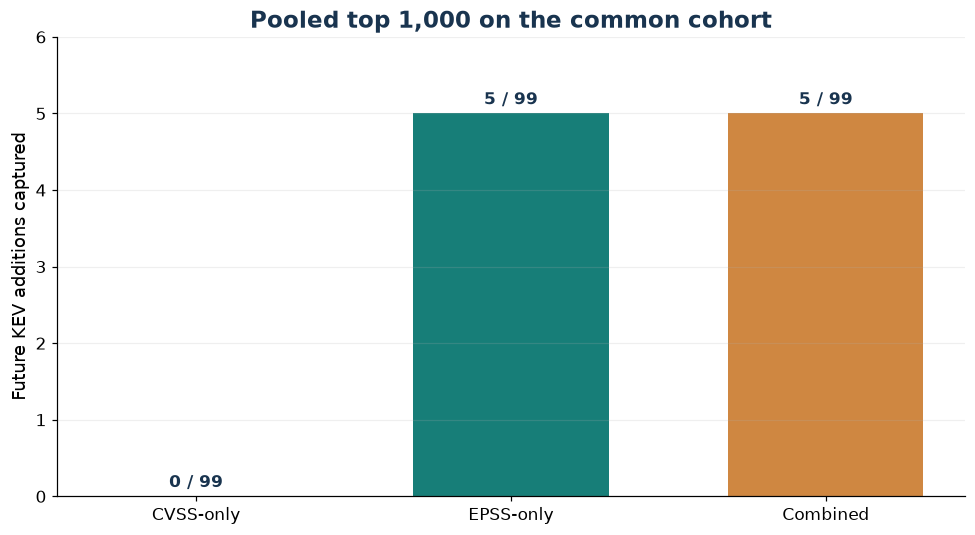

,Ranking,Common-cohort rows,Positives,"Recall@1,000","Precision@1,000",Recall CI low,Recall CI high
255,CVSS-only,"859,971",99,0.00%,0.00%,0.00%,0.00%
259,EPSS-only,"859,971",99,5.05%,0.50%,0.99%,9.72%
263,Combined,"859,971",99,5.05%,0.50%,1.42%,9.19%


In [28]:
# Headline view: each decision date has equal weight; bands show the observed date range.
per_date = ranking.query("decision_date != 'POOLED' and cohort == 'common_v3_epss'").copy()
per_date_summary_common = per_date_summary.query("cohort == 'common_v3_epss'")
fig, ax = plt.subplots(figsize=(10,5.5))
for method, color in zip(method_order, colors):
    part=per_date.loc[per_date.method.eq(method)].groupby("k",as_index=False).agg(mean=("recall_at_k","mean"),low=("recall_at_k","min"),high=("recall_at_k","max")).sort_values("k")
    ax.plot(part.k,part["mean"]*100,marker="o",linewidth=2.5,label=method,color=color)
    ax.fill_between(part.k,part.low*100,part.high*100,color=color,alpha=.10)
ax.set(title="Mean per-date Recall@K (headline)",xlabel="Patching budget K",ylabel="Mean date-level Recall@K (%)")
ax.set_xticks([50,100,500,1000]); ax.set_ylim(0,100); ax.grid(alpha=.2); ax.legend(frameon=False)
fig.tight_layout(); plt.show()
display(per_date_summary_common[["method","k","dates","mean_recall_at_k","mean_precision_at_k","min_recall_at_k","max_recall_at_k"]].sort_values(["k","method"]).style.format({"mean_recall_at_k":"{:.3f}","mean_precision_at_k":"{:.4%}","min_recall_at_k":"{:.3f}","max_recall_at_k":"{:.3f}"}))

**Interpretation:** This is the headline comparison: it gives each decision date equal weight and shows the spread across dates. Expected metrics average over ties, so cutoffs inside large tie groups do not depend on CVE row order.

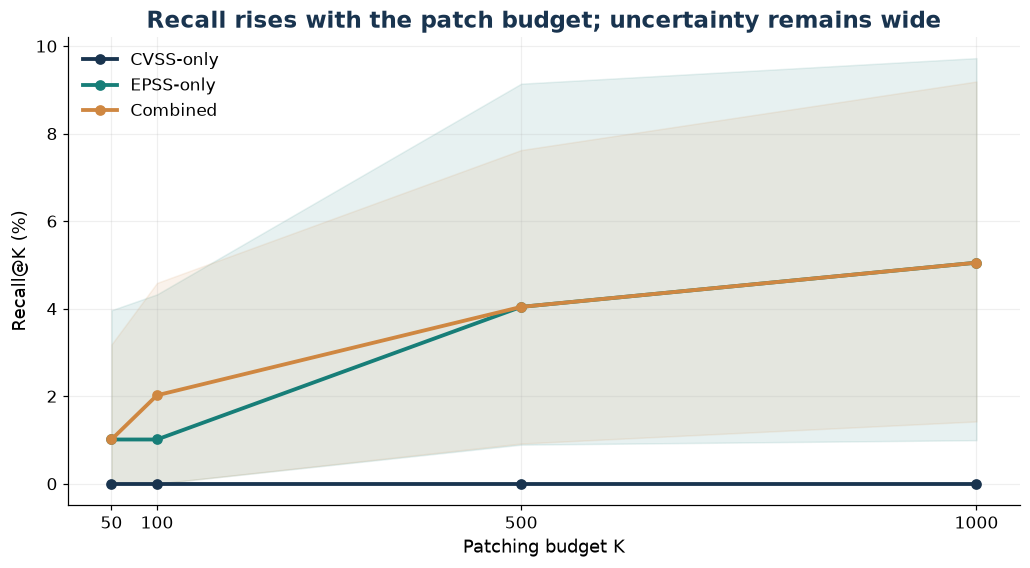

In [29]:
# Secondary view: pooled CVE-date opportunities retain repeated CVEs across dates.
common = ranking.query("decision_date == 'POOLED' and cohort == 'common_v3_epss'").copy()
pooled_curve=common.loc[common.method.isin(method_order)].copy()
pooled_curve["method"]=pd.Categorical(pooled_curve["method"],method_order,ordered=True)
fig,ax=plt.subplots(figsize=(8,4.8))
for method,color in zip(method_order,colors):
    part=pooled_curve.loc[pooled_curve.method.eq(method)].sort_values("k")
    ax.plot(part.k,part.recall_at_k*100,marker="o",linewidth=2,label=method,color=color)
    ax.fill_between(part.k,part.recall_ci_low*100,part.recall_ci_high*100,color=color,alpha=.10)
ax.set_xlabel("Patching budget K"); ax.set_ylabel("Pooled Recall@K (%)")
ax.set_title("Secondary view: pooled decision opportunities")
ax.set_xticks([50,100,500,1000]); ax.grid(alpha=.2); ax.legend(frameon=False)
fig.tight_layout(); plt.show()
display(common.loc[common.k.eq(1000),["method","pool_size","positives_in_pool","recall_at_k","precision_at_k","recall_ci_low","recall_ci_high"]].style.format({"pool_size":"{:,.0f}","positives_in_pool":"{:,.0f}","recall_at_k":"{:.3f}","precision_at_k":"{:.4%}","recall_ci_low":"{:.3f}","recall_ci_high":"{:.3f}"}))

### Pooled results as a secondary view

The pooled values combine decision opportunities from all dates, so CVEs that recur remain in the analysis. They answer an across-snapshot question and should not be read as a single deployment queue.

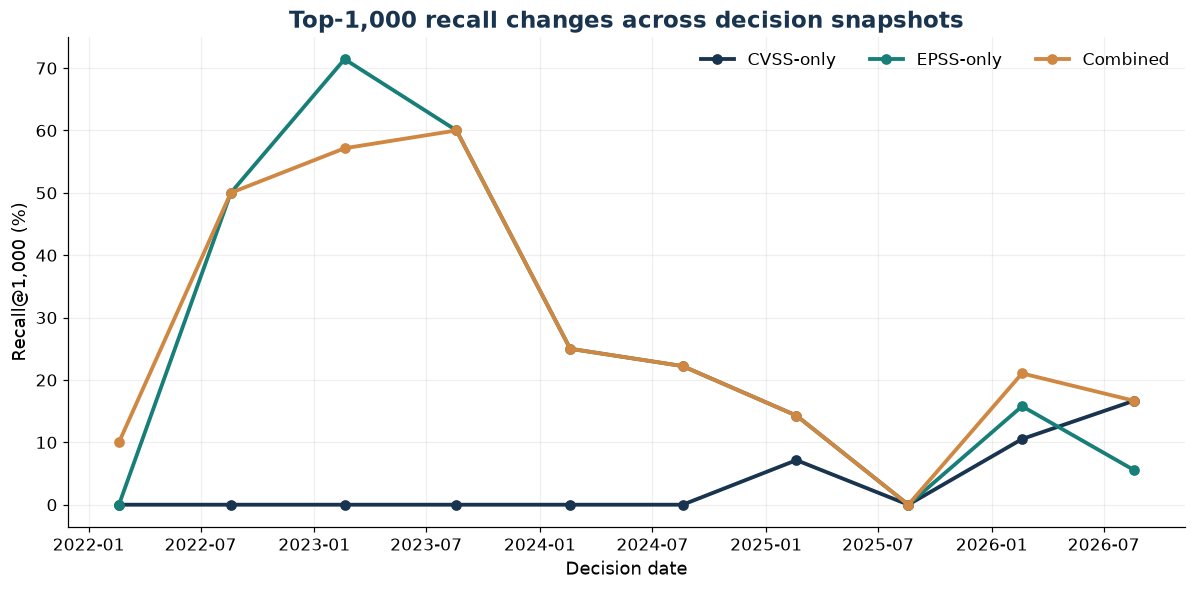

In [30]:
by_date=per_date.loc[per_date.k.eq(1000)].copy()
by_date["decision_date"]=pd.to_datetime(by_date["decision_date"])
wide=by_date.pivot(index="decision_date",columns="method",values="recall_at_k").sort_index()
fig,ax=plt.subplots(figsize=(11,5.5))
for method,color in zip(method_order,colors):
    ax.plot(wide.index,wide[method]*100,marker="o",linewidth=2.5,label=method,color=color)
ax.set_ylabel("Expected Recall@1,000 (%)"); ax.set_xlabel("Decision date")
ax.set_title("Date-to-date variation at the 1,000-item budget")
ax.set_ylim(0,100); ax.grid(alpha=.2); ax.legend(frameon=False,ncol=3)
fig.tight_layout(); plt.show()

## 4. What do the tests say?

EPSS scores are higher among positive rows in the pooled one-sided Mann–Whitney test. For H2 and H3, pooled recall differences at _K_ = 1,000 are positive before correction, but neither survives Holm adjustment across the planned dates and budgets.

**Presenter cue:** Separate “the observed ranking did better in this sample” from “we have strong evidence of a stable advantage.” The project supports the first statement more than the second.

In [31]:
pooled_tests = tests.loc[tests["decision_date"].eq("POOLED")].copy()
h1 = pooled_tests.loc[pooled_tests["hypothesis"].str.startswith("H1")]
h23 = pooled_tests.loc[
    pooled_tests["hypothesis"].str.startswith(("H2", "H3"))
    & pooled_tests["test"].str.endswith("K=1000")
]
selected_tests = pd.concat([h1, h23], ignore_index=True)
selected_tests["hypothesis"] = selected_tests["hypothesis"].str.extract(r"^(H[1-3])")
display(selected_tests[["hypothesis", "effect", "ci_low", "ci_high", "p_value", "p_holm_within_hypothesis", "positives"]].rename(columns={
    "hypothesis": "Test", "effect": "Effect", "ci_low": "95% CI low", "ci_high": "95% CI high",
    "p_value": "Raw p", "p_holm_within_hypothesis": "Holm-adjusted p", "positives": "Positive rows"
}).style.format({"Effect": "{:.4f}", "95% CI low": "{:.4f}", "95% CI high": "{:.4f}", "Raw p": "{:.3g}", "Holm-adjusted p": "{:.3g}", "Positive rows": "{:,.0f}"}))

,Test,Effect,95% CI low,95% CI high,Raw p,Holm-adjusted p,Positive rows
0,H1,0.0072,nan,nan,2.72e-11,2.99e-10,109
1,H2,0.0505,0.0098,0.0930,0.0166,0.648,99
2,H3,0.0505,0.0114,0.0943,0.0166,0.664,99


## 5. A time-forward model check

Logistic Regression, Random Forest, and XGBoost were trained through August 2025, validated on February 2026, and tested on August 2026. The with-EPSS feature set adds decision-date EPSS probability and percentile. Both use historical CVSS features and CVE age; current NVD enrichment fields are excluded.

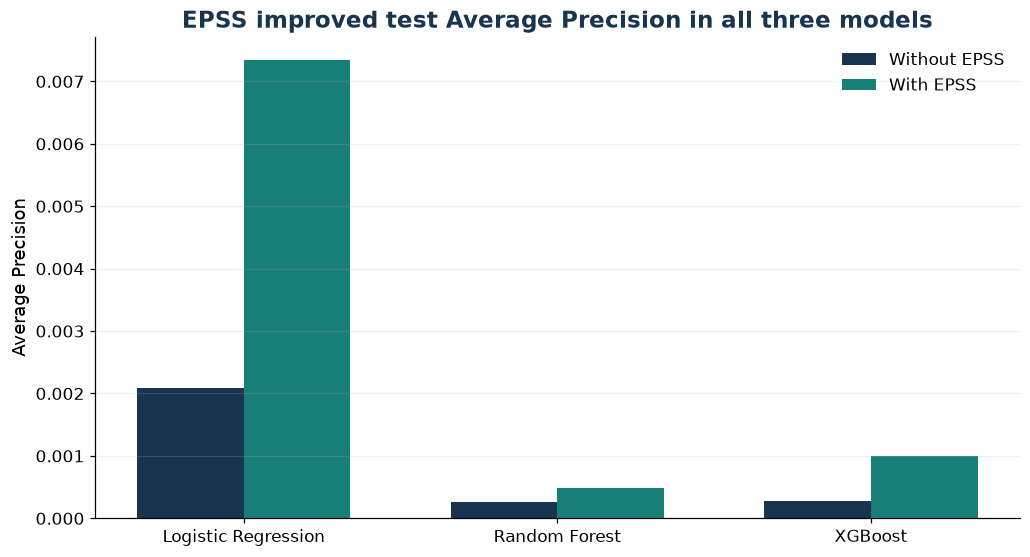

,Model,Features,Test rows,Positives,Average Precision
7,Logistic Regression,With EPSS,"206,587",19,0.007346
1,Logistic Regression,Without EPSS,"206,587",19,0.002086
9,Random Forest,With EPSS,"206,587",19,0.000483
3,Random Forest,Without EPSS,"206,587",19,0.000253
11,XGBoost,With EPSS,"206,587",19,0.000991
5,XGBoost,Without EPSS,"206,587",19,0.000269


In [32]:
test_models = models.loc[models["split"].eq("test")].copy()
model_order = ["Logistic Regression", "Random Forest", "XGBoost"]
model_pivot = test_models.pivot(index="model", columns="feature_set", values="average_precision").reindex(model_order)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
xs = range(len(model_pivot))
width = .34
without = model_pivot["Without EPSS"].to_numpy()
with_epss = model_pivot["With EPSS"].to_numpy()
ax.bar([x - width/2 for x in xs], without, width, label="Without EPSS", color=NAVY)
ax.bar([x + width/2 for x in xs], with_epss, width, label="With EPSS", color=TEAL)
ax.set_xticks(list(xs), model_order)
ax.set_ylabel("Average Precision")
ax.set_title("EPSS improved test Average Precision in all three models", color=NAVY)
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

display(test_models[["model", "feature_set", "rows", "positives", "average_precision"]].sort_values(["model", "feature_set"]).rename(columns={
    "model": "Model", "feature_set": "Features", "rows": "Test rows", "positives": "Positives", "average_precision": "Average Precision"
}).style.format({"Test rows": "{:,.0f}", "Positives": "{:,.0f}", "Average Precision": "{:.6f}"}))

**Readout:** Average Precision increased for all three model families on the August 2026 holdout. That test period has only 19 positives, so this is promising but provisional evidence, not proof of stable performance.

## 6. Recommendation and closing

### Recommendation

Use EPSS as an **advisory signal in a shadow-mode pilot**. Keep CVSS, asset context, exposure, compensating controls, and patch feasibility visible to analysts. Evaluate the lists without changing patch decisions first.

### Three points to leave with the audience

1. The backtest uses date-specific EPSS and reconstructed historical CVSS, reducing future-information leakage.
2. EPSS-inclusive rankings capture more top-1,000 positives in the pooled sample, but the adjusted tests do not establish a reliable advantage.
3. More periods and organization-specific asset context are needed before changing patch policy.

### Important limitations

- KEV `dateAdded` is a catalogue date, not the time of the first real-world attack.
- Positive labels are rare, and the same CVE can appear at multiple dates.
- Historical CVSS 3.x coverage is incomplete; missing scores remain missing.
- Results describe association and prediction in this dataset, not a causal security impact.

**Suggested closing:** “EPSS is worth evaluating alongside CVSS, but our evidence supports a measured pilot rather than automatic reprioritization.”

## Sources and project files

- NVD CVE data feeds and change history
- FIRST EPSS dated snapshots
- CISA KEV catalogue
- Project report: docs/final_report.pdf
- Hypothesis assessment: docs/hypothesis_assessment.md
- Generated ranking and model tables: outputs/tables/

**Run setup:** The analysis section above this presentation narrative loads `data/processed/ssot_historical.csv` and refits six models in cells 12–13. It requires the processed historical panel and may take several minutes. The presentation walkthrough beginning at “Beyond CVSS” reads saved tables under `outputs/tables/`; it does not download source files or retrain models.